In [1]:
# import the necessary libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA

In [2]:
## import and read the dataset
data=pd.read_csv('credit_card.csv')
data.head()

,actionnr,merchant_id,average_amount_transaction_day,transaction_amount,is_declined,total_number_of_declines_day,isforeigntransaction,ishighriskcountry,daily_chargeback_avg_amt,sixmonth_avg_chbk_amt,sixmonth_chbk_freq,isfradulent
0,1,3160040998,100.0,3000.0,N,5,Y,Y,0,0.0,0,Y
1,2,3160040998,100.0,4300.0,N,5,Y,Y,0,0.0,0,Y
2,3,3160041896,185.5,4823.0,Y,5,N,N,0,0.0,0,Y
3,4,3160141996,185.5,5008.5,Y,8,N,N,0,0.0,0,Y
4,5,3160241992,500.0,26000.0,N,0,Y,Y,800,677.2,6,Y


In [3]:
## 

In [4]:
type(data)

pandas.core.frame.DataFrame

In [5]:
# Remove the target column from the dataset
data=data.drop(columns=['actionnr','merchant_id','isfradulent'])
data.head()

,average_amount_transaction_day,transaction_amount,is_declined,total_number_of_declines_day,isforeigntransaction,ishighriskcountry,daily_chargeback_avg_amt,sixmonth_avg_chbk_amt,sixmonth_chbk_freq
0,100.0,3000.0,N,5,Y,Y,0,0.0,0
1,100.0,4300.0,N,5,Y,Y,0,0.0,0
2,185.5,4823.0,Y,5,N,N,0,0.0,0
3,185.5,5008.5,Y,8,N,N,0,0.0,0
4,500.0,26000.0,N,0,Y,Y,800,677.2,6


In [6]:
## Identify the dataframe structure to  evaluvate meta data, assess the data quality, and understand of the dataset composition
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3075 entries, 0 to 3074
Data columns (total 9 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   average_amount_transaction_day  3075 non-null   float64
 1   transaction_amount              3075 non-null   float64
 2   is_declined                     3075 non-null   object 
 3   total_number_of_declines_day    3075 non-null   int64  
 4   isforeigntransaction            3075 non-null   object 
 5   ishighriskcountry               3075 non-null   object 
 6   daily_chargeback_avg_amt        3075 non-null   int64  
 7   sixmonth_avg_chbk_amt           3075 non-null   float64
 8   sixmonth_chbk_freq              3075 non-null   int64  
dtypes: float64(3), int64(3), object(3)
memory usage: 216.3+ KB


In [7]:
## Rename the columns of the dataframe

In [8]:
# Print all column names as a list so you can see them clearly
print(data.columns.tolist())
for  i in data.columns.tolist():
    print(i)

['average_amount_transaction_day', 'transaction_amount', 'is_declined', 'total_number_of_declines_day', 'isforeigntransaction', 'ishighriskcountry', 'daily_chargeback_avg_amt', 'sixmonth_avg_chbk_amt', 'sixmonth_chbk_freq']
average_amount_transaction_day
transaction_amount
is_declined
total_number_of_declines_day
isforeigntransaction
ishighriskcountry
daily_chargeback_avg_amt
sixmonth_avg_chbk_amt
sixmonth_chbk_freq


In [9]:
data = data.rename(columns={"average_amount_transaction_day":"average_amount_transaction_day","transaction_amount":"transaction_amount","is_declined":"is_declined","total_number_of_declines_day":"total_number_of_declines_day","isforeigntransaction": "is_foreign_transaction", "ishighriskcountry": "is_high_risk_country","daily_chargeback_avg_amt":"daily_chargeback_avg_amt", "sixmonth_avg_chbk_amt":"sixmonth_avg_chbk_amt","sixmonth_chbk_freq":"sixmoth_chbk_freq"})
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3075 entries, 0 to 3074
Data columns (total 9 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   average_amount_transaction_day  3075 non-null   float64
 1   transaction_amount              3075 non-null   float64
 2   is_declined                     3075 non-null   object 
 3   total_number_of_declines_day    3075 non-null   int64  
 4   is_foreign_transaction          3075 non-null   object 
 5   is_high_risk_country            3075 non-null   object 
 6   daily_chargeback_avg_amt        3075 non-null   int64  
 7   sixmonth_avg_chbk_amt           3075 non-null   float64
 8   sixmoth_chbk_freq               3075 non-null   int64  
dtypes: float64(3), int64(3), object(3)
memory usage: 216.3+ KB


In [10]:
data.head()

,average_amount_transaction_day,transaction_amount,is_declined,total_number_of_declines_day,is_foreign_transaction,is_high_risk_country,daily_chargeback_avg_amt,sixmonth_avg_chbk_amt,sixmoth_chbk_freq
0,100.0,3000.0,N,5,Y,Y,0,0.0,0
1,100.0,4300.0,N,5,Y,Y,0,0.0,0
2,185.5,4823.0,Y,5,N,N,0,0.0,0
3,185.5,5008.5,Y,8,N,N,0,0.0,0
4,500.0,26000.0,N,0,Y,Y,800,677.2,6


In [11]:
## Converting the categorical attributes into  numerical values

In [12]:
#encoder=OneHotEncoder(sparse_output=False,dtype=int)

In [13]:
#encoded_data=encoder.fit_transform(data[['is_declined','is_foreign_transaction','is_high_risk_country']])
#encoded_data

In [14]:
#encoded_df = pd.DataFrame(
 #   encoded_data,
#)

#print(encoded_df.head())

In [15]:
cols = ['is_declined','is_foreign_transaction','is_high_risk_country']

encoder = OneHotEncoder(
    sparse_output=False,
    drop='if_binary',
    handle_unknown='ignore'
)

encoded_data = encoder.fit_transform(data[cols])
## Get the feature names                                 
feature_names = encoder.get_feature_names_out(cols)
## converting the encoded data  into  pandas dataframe
encoded_df = pd.DataFrame(encoded_data, columns=feature_names, index=data.index)
# Drop the old unencoded columns and join the new named columns
data = data.drop(columns=cols)
data
# Concatenate the  encoded dataframe with original dataframe
data = pd.concat([data, encoded_df], axis=1)
data.head()

#Replace values in the same columns
#data[cols] = encoded_data

#data.head()

,average_amount_transaction_day,transaction_amount,total_number_of_declines_day,daily_chargeback_avg_amt,sixmonth_avg_chbk_amt,sixmoth_chbk_freq,is_declined_Y,is_foreign_transaction_Y,is_high_risk_country_Y
0,100.0,3000.0,5,0,0.0,0,0.0,1.0,1.0
1,100.0,4300.0,5,0,0.0,0,0.0,1.0,1.0
2,185.5,4823.0,5,0,0.0,0,1.0,0.0,0.0
3,185.5,5008.5,8,0,0.0,0,1.0,0.0,0.0
4,500.0,26000.0,0,800,677.2,6,0.0,1.0,1.0


In [16]:
## check the correlational coefficient

In [17]:
data.corr()

,average_amount_transaction_day,transaction_amount,total_number_of_declines_day,daily_chargeback_avg_amt,sixmonth_avg_chbk_amt,sixmoth_chbk_freq,is_declined_Y,is_foreign_transaction_Y,is_high_risk_country_Y
average_amount_transaction_day,1.000000,0.587111,-0.009682,0.060429,0.060284,0.071849,0.081184,0.047316,0.014604
transaction_amount,0.587111,1.000000,0.259309,0.252298,0.259663,0.297623,0.197009,0.276764,0.325397
total_number_of_declines_day,-0.009682,0.259309,1.000000,0.094834,0.081138,0.085028,0.115961,0.227904,0.292459
daily_chargeback_avg_amt,0.060429,0.252298,0.094834,1.000000,0.953663,0.884611,0.394083,0.054798,0.074902
sixmonth_avg_chbk_amt,0.060284,0.259663,0.081138,0.953663,1.000000,0.851339,0.407917,0.060566,0.073167
sixmoth_chbk_freq,0.071849,0.297623,0.085028,0.884611,0.851339,1.000000,0.499365,0.077083,0.098241
is_declined_Y,0.081184,0.197009,0.115961,0.394083,0.407917,0.499365,1.000000,0.079761,0.127586
is_foreign_transaction_Y,0.047316,0.276764,0.227904,0.054798,0.060566,0.077083,0.079761,1.000000,0.489572
is_high_risk_country_Y,0.014604,0.325397,0.292459,0.074902,0.073167,0.098241,0.127586,0.489572,1.000000


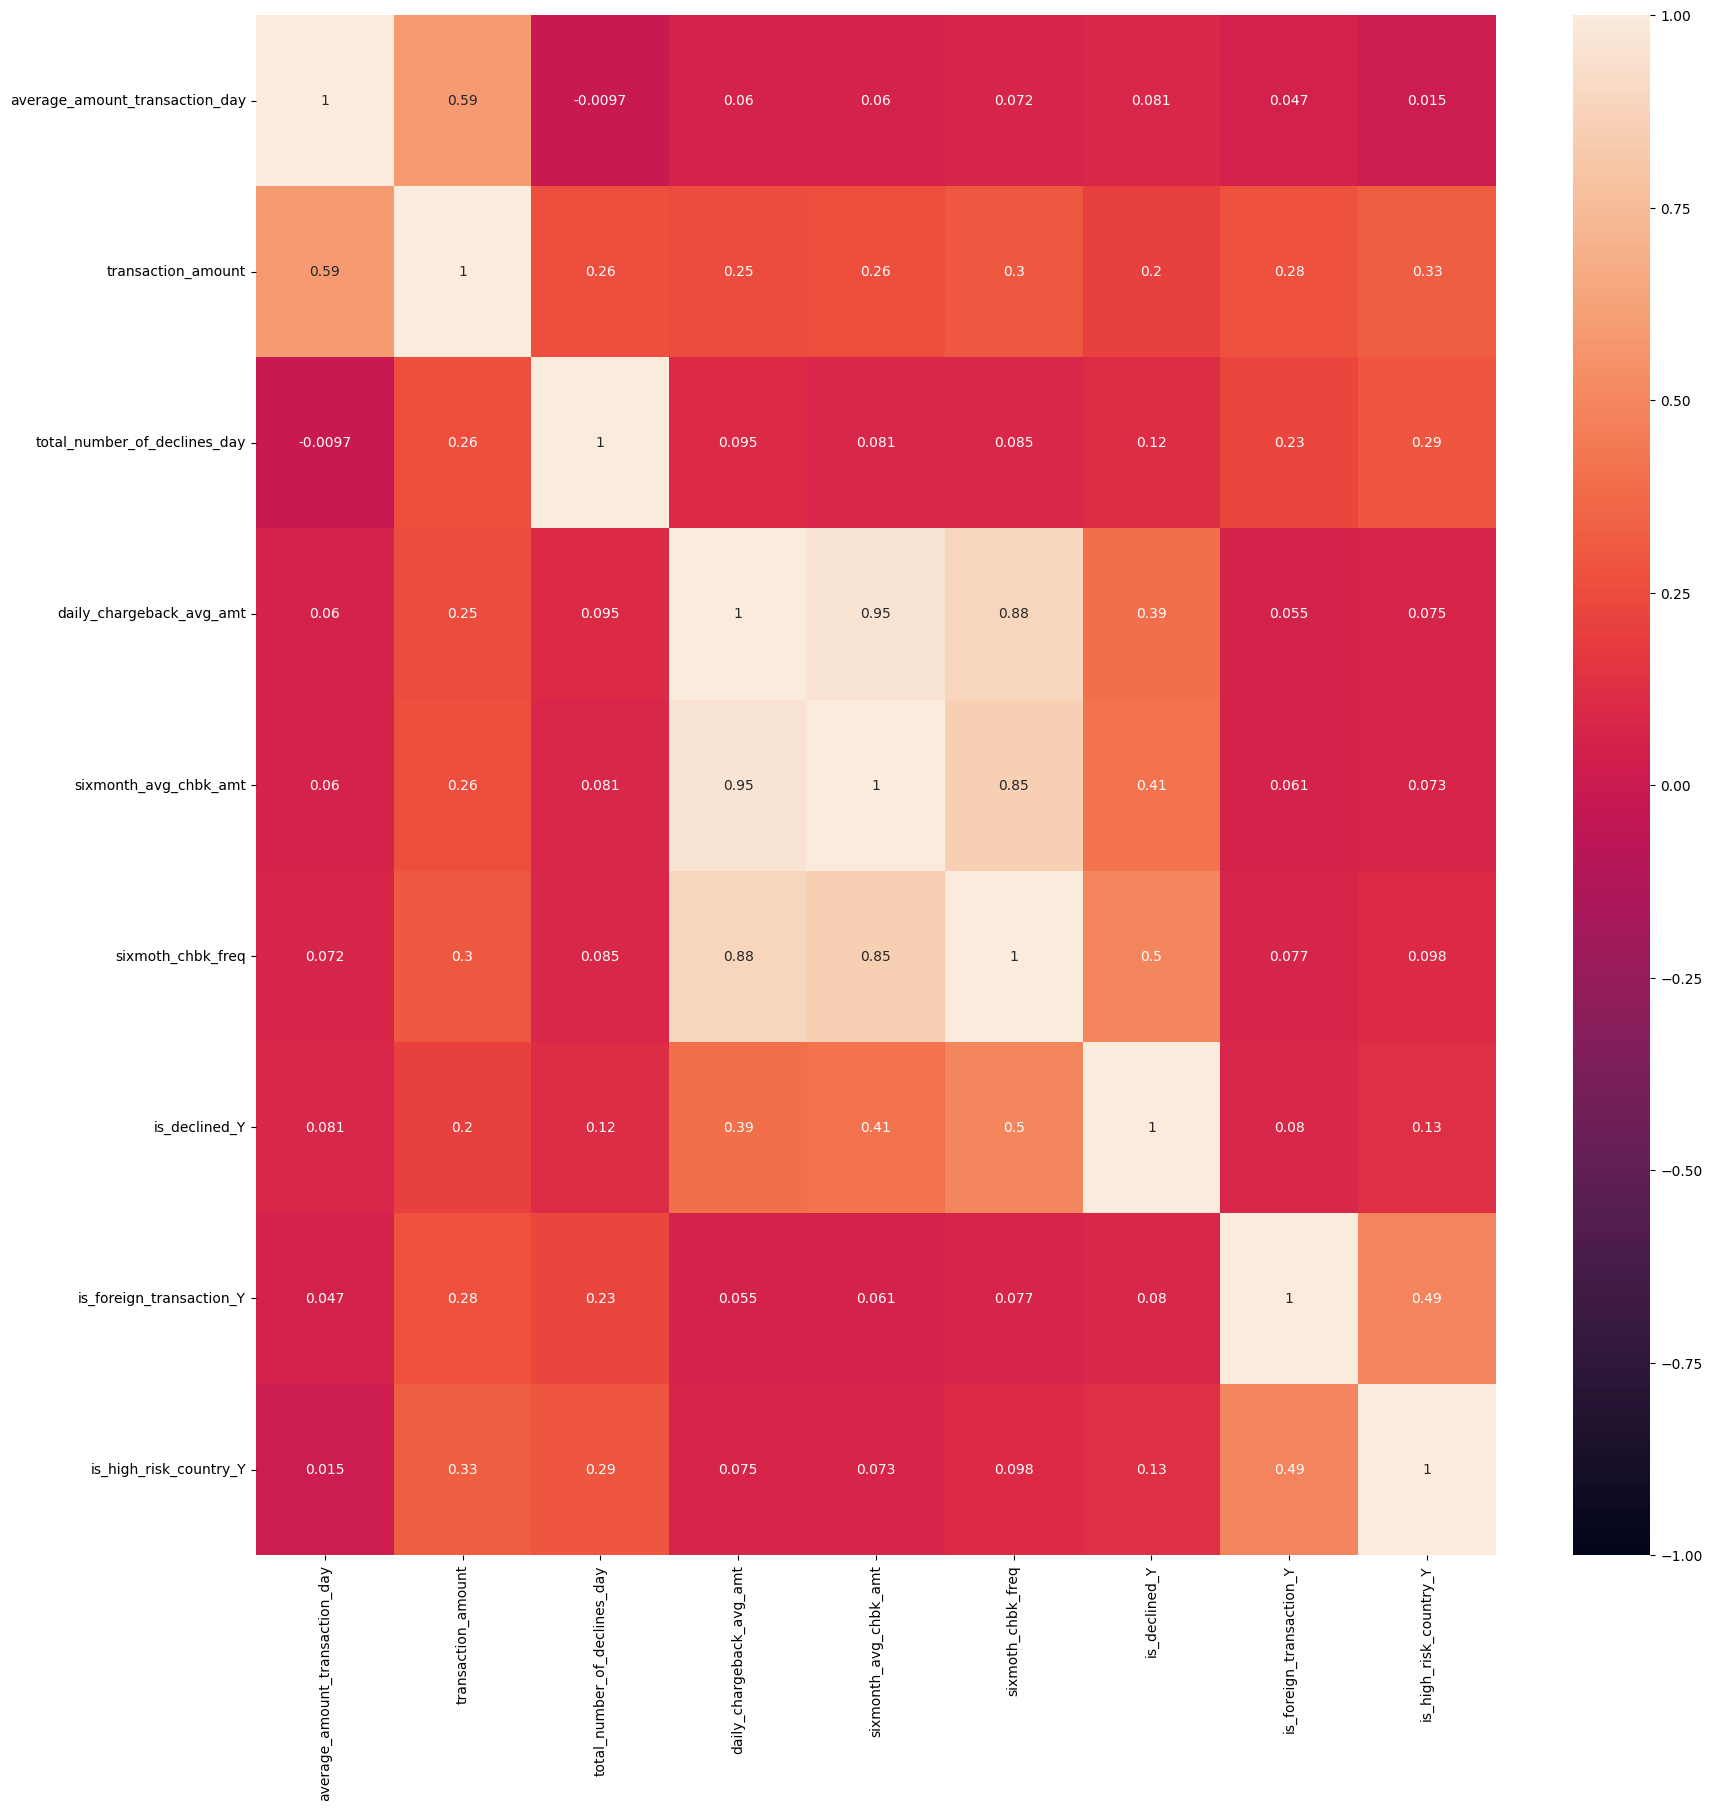

In [18]:
## Graphical represent the  correlational coefficient using heatmap
plt.figure(figsize=(20,20))
sns.heatmap(data.corr(),annot=True,vmin=-1, vmax=1)
plt.show()

#                                              Correlational Coefficiency Spectrum
#### According to the above correlational coefficient matrix and  its graphical representation (heatmap)   mainly  represented  coefficiency between features
#### when it comes to the clustering scenario these variables  cofficiency is important. To measure the coefficient coefficiency
#### we have to use correlational coefficient spectrum. 
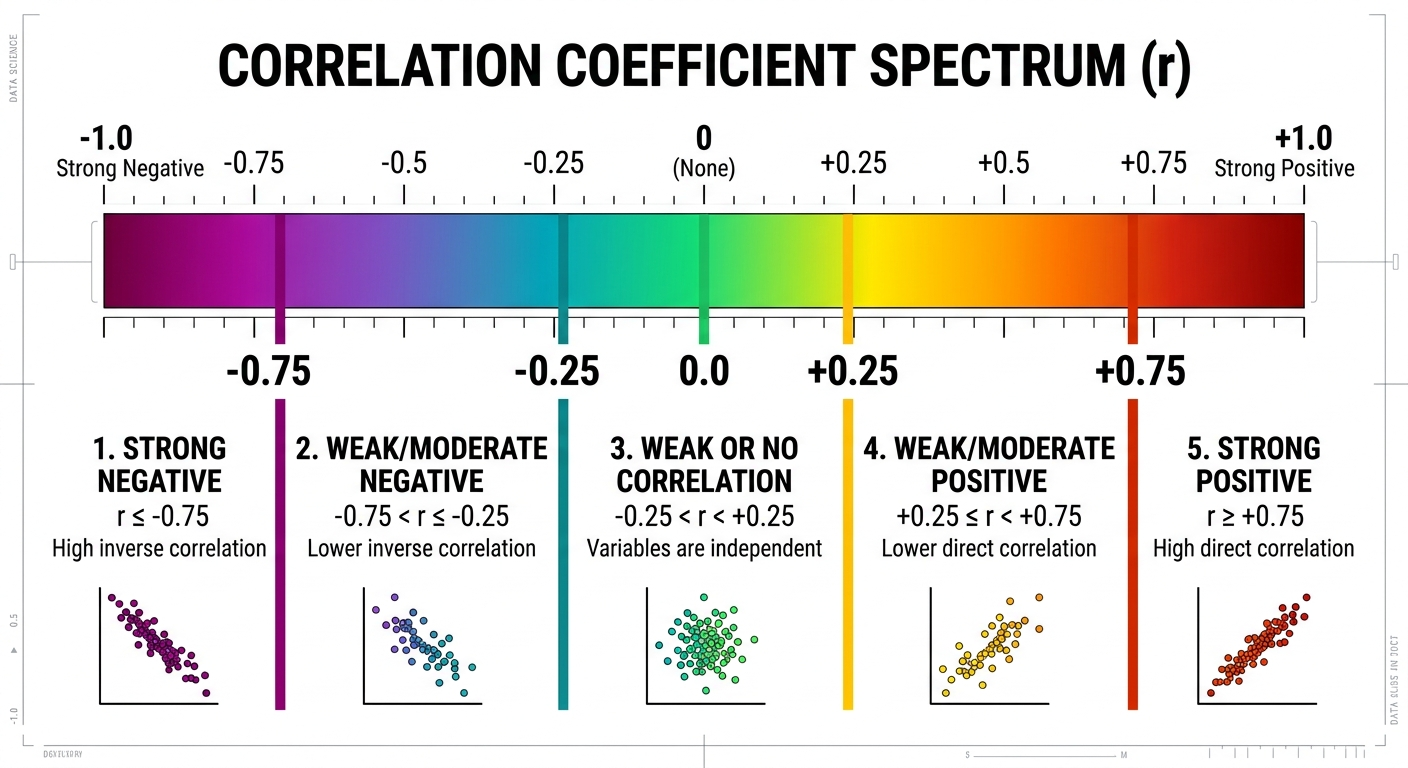

#### According to the above spectrum, we consider  strong correlational, and moderate  correlational features in positive side and negative side